#   vérification avec PyTorch

PyTorch sert ici **uniquement de référence** : le réseau, la rétropropagation et les optimiseurs restent ceux écrits en NumPy (parties B, C et E). On vérifie que les deux implémentations calculent la même chose.

**Protocole**

1. Même architecture $2 \to 16 \to 8 \to 1$ (ReLU, ReLU, sigmoïde) et même loss (BCE moyenne).
2. **Mêmes poids initiaux** : le réseau PyTorch reçoit une copie des poids du modèle NumPy.
3. **Mêmes mini-batchs** : les deux modèles voient les mêmes exemples dans le même ordre, à chaque pas.
4. Calculs en **float64** des deux côtés pour la comparaison exacte, puis en float32 côté PyTorch pour voir l'effet de la précision.
5. Comparaisons demandées : notre SGD ↔ `torch.optim.SGD`, notre Adam ↔ `torch.optim.Adam`, avec les mêmes hyperparamètres que dans les parties C et D (SGD lr = 0.1, Adam lr = 0.003, $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\varepsilon = 10^{-8}$).

Le Momentum est ajouté en complément, car sa convention diffère de celle de PyTorch (section 4).

In [2]:
import sys, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
sys.path.append('..')
from src.data import load_data
from src.model import MLP
from src.losses import bce
from src.optimizers import SGD, Momentum, Adam

data = load_data(seed=42)
X, y = data['X_train'], data['y_train']
SEEDS = [0, 1, 2, 3, 4]
EPOCHS, BATCH = 500, 32
print('PyTorch', torch.__version__)

PyTorch 2.14.1+cu130


In [3]:
def to_torch(model_np, dtype=torch.float64):
    # réseau PyTorch équivalent, initialisé avec une copie des poids NumPy
    lins = model_np.linear_layers()
    mods = []
    for i, l in enumerate(lins):
        n_out = np.size(l.b); n_in = l.W.size // n_out
        mods.append(nn.Linear(n_in, n_out))
        mods.append(nn.ReLU() if i < len(lins) - 1 else nn.Sigmoid())
    net = nn.Sequential(*mods).to(dtype)
    with torch.no_grad():
        for tl, l in zip(torch_linears(net), lins):
            tl.weight.copy_(torch.as_tensor(aligned(l.W, tl), dtype=dtype))
            tl.bias.copy_(torch.as_tensor(np.ravel(l.b), dtype=dtype))
    return net

def torch_linears(net):
    return [m for m in net if isinstance(m, nn.Linear)]

def aligned(W, tl):
    # PyTorch stocke W avec la forme (sorties, entrées) ; on transpose si notre convention est (entrées, sorties)
    return W if W.shape == tuple(tl.weight.shape) else W.T

def max_param_diff(model_np, net):
    # plus grand écart absolu entre les paramètres des deux modèles
    d = 0.0
    for tl, l in zip(torch_linears(net), model_np.linear_layers()):
        d = max(d, np.abs(aligned(l.W, tl) - tl.weight.detach().double().numpy()).max(),
                   np.abs(np.ravel(l.b) - tl.bias.detach().double().numpy()).max())
    return d

def tt(a, dtype=torch.float64, shape=None):
    t = torch.as_tensor(a, dtype=dtype)
    return t.reshape(shape) if shape is not None else t

bce_t = nn.BCELoss()

## 1. Forward, loss et gradients (même point $\theta$)

On compare, sur tout le jeu d'entraînement : la sortie du réseau, la BCE, puis les gradients de notre rétropropagation avec ceux d'autograd. Erreur relative : $\|g_{NumPy} - g_{torch}\| / (\|g_{NumPy}\| + \|g_{torch}\|)$, comme pour le gradient checking de la partie B.

In [4]:
rows = []
for s in SEEDS:
    m = MLP(seed=s); net = to_torch(m)
    m.eval()
    p_np = m.forward(X)
    p_t = net(tt(X))
    loss_t = bce_t(p_t, tt(y, shape=p_t.shape))
    loss_t.backward()
    m.loss_and_grad(X, y)
    err = []
    for tl, l in zip(torch_linears(net), m.linear_layers()):
        for g_np, g_t in [(aligned(l.dW, tl), tl.weight.grad.numpy()), (np.ravel(l.db), tl.bias.grad.numpy())]:
            err.append(np.linalg.norm(g_np - g_t) / (np.linalg.norm(g_np) + np.linalg.norm(g_t) + 1e-300))
    rows.append({'seed': s, 'écart max sortie ŷ': np.abs(p_np.ravel() - p_t.detach().numpy().ravel()).max(),
                 'écart loss': abs(bce(p_np, y) - loss_t.item()), 'erreur relative max des gradients': max(err)})
g0 = pd.DataFrame(rows).set_index('seed')
g0

,écart max sortie ŷ,écart loss,erreur relative max des gradients
seed,,,
0,1.110223e-16,1.110223e-16,3.522740e-16
1,2.220446e-16,1.110223e-16,5.824646e-16
2,2.220446e-16,0.000000e+00,4.008781e-16
3,2.775558e-16,2.220446e-16,3.484235e-16
4,1.110223e-16,2.220446e-16,3.666650e-16


## 2. Entraînement pas à pas : notre optimiseur contre `torch.optim`

À chaque pas, les deux modèles reçoivent le même mini-batch. On mesure le plus grand écart entre leurs paramètres après chaque pas, et les loss train et validation à chaque époque.

In [5]:
def compare_run(make_np_opt, make_t_opt, seed, epochs=EPOCHS, dtype=torch.float64):
    m = MLP(seed=seed); net = to_torch(m, dtype)
    opt_np, opt_t = make_np_opt(), make_t_opt(net.parameters())
    Xt, yt = tt(X, dtype), tt(y, dtype)
    Xv, yv = tt(data['X_val'], dtype), data['y_val']
    rng = np.random.default_rng(seed); n = len(X)
    steps, h = [], {k: [] for k in ['lt_np', 'lt_t', 'lv_np', 'lv_t', 'av_np', 'av_t', 'diff']}
    t_np = t_t = 0.0
    for ep in range(epochs):
        idx = rng.permutation(n)
        for s0 in range(0, n, BATCH):
            b = idx[s0:s0 + BATCH]
            t0 = time.perf_counter()
            m.train(); m.loss_and_grad(X[b], y[b])
            theta = opt_np.step(m.get_params(), m.get_grads())
            m.set_params(theta)
            t1 = time.perf_counter()
            opt_t.zero_grad()
            p = net(Xt[b]); bce_t(p, yt[b].reshape(p.shape)).backward()
            opt_t.step()
            t2 = time.perf_counter()
            t_np += t1 - t0; t_t += t2 - t1
            steps.append(max_param_diff(m, net))
        m.eval()
        with torch.no_grad():
            pt_tr, pt_va = net(Xt).double().numpy(), net(Xv).double().numpy()
        p_tr, p_va = m.forward(X), m.forward(data['X_val'])
        h['lt_np'].append(bce(p_tr, y)); h['lt_t'].append(bce(pt_tr.reshape(p_tr.shape), y))
        h['lv_np'].append(bce(p_va, yv)); h['lv_t'].append(bce(pt_va.reshape(p_va.shape), yv))
        h['av_np'].append(np.mean((p_va.ravel() > .5) == (yv.ravel() > .5)))
        h['av_t'].append(np.mean((pt_va.ravel() > .5) == (yv.ravel() > .5)))
        h['diff'].append(steps[-1])
    h = {k: np.array(v) for k, v in h.items()}
    h['steps'] = np.array(steps); h['time_np'] = t_np; h['time_t'] = t_t
    return h

CASES = {
    'SGD':  (lambda: SGD(lr=0.1),   lambda p: torch.optim.SGD(p, lr=0.1)),
    'Adam': (lambda: Adam(lr=0.003), lambda p: torch.optim.Adam(p, lr=0.003, betas=(0.9, 0.999), eps=1e-8)),
}
runs = {}
for name, (mk_np, mk_t) in CASES.items():
    for s in SEEDS:
        runs[name, 'float64', s] = compare_run(mk_np, mk_t, s)
    runs[name, 'float32', 0] = compare_run(mk_np, mk_t, 0, dtype=torch.float32)
print('ok')

ok


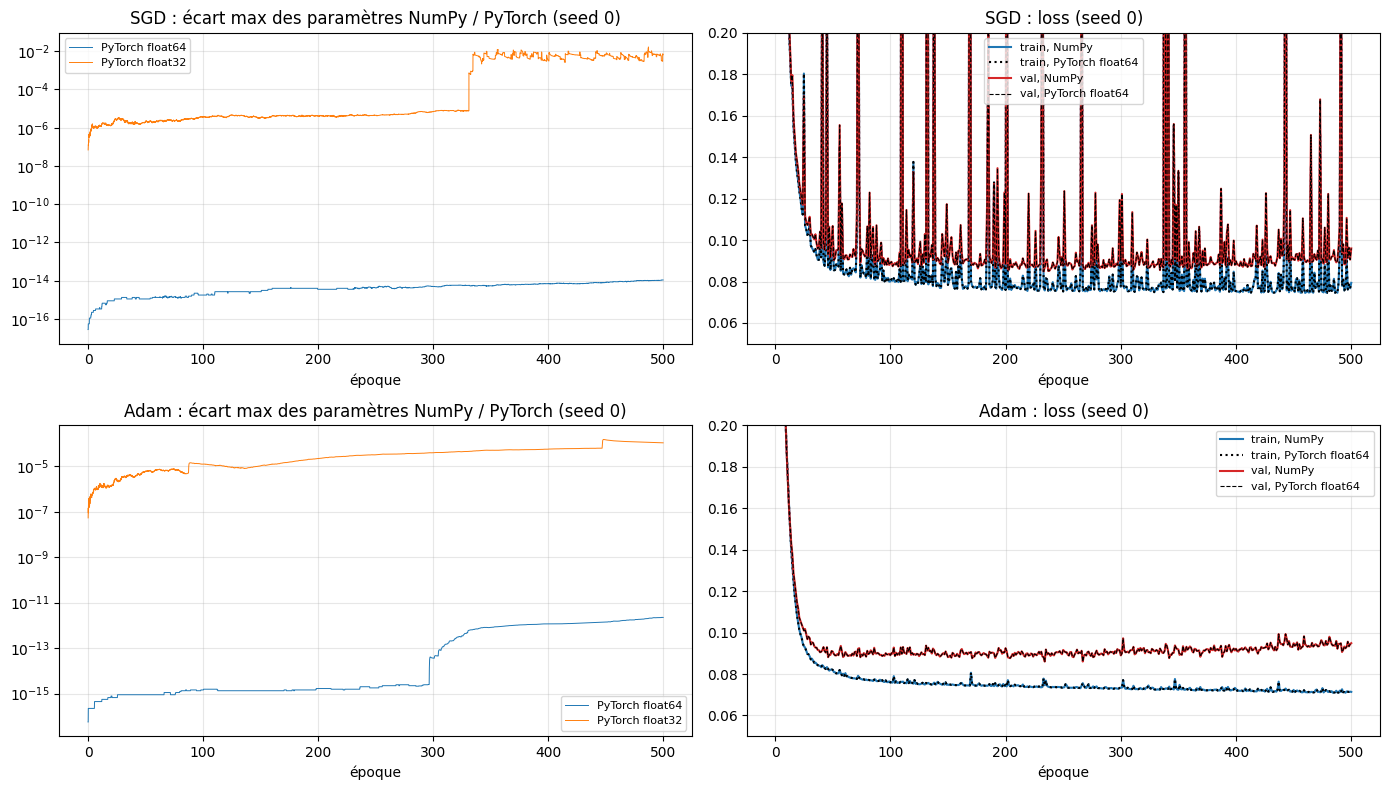

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
for i, name in enumerate(CASES):
    r64, r32 = runs[name, 'float64', 0], runs[name, 'float32', 0]
    spe = len(r64['steps']) / EPOCHS
    x = np.arange(1, len(r64['steps']) + 1) / spe
    ax[i, 0].semilogy(x, np.maximum(r64['steps'], 1e-17), lw=.7, label='PyTorch float64')
    ax[i, 0].semilogy(x, np.maximum(r32['steps'], 1e-17), lw=.7, color='tab:orange', label='PyTorch float32')
    ax[i, 0].set(title=f'{name} : écart max des paramètres NumPy / PyTorch (seed 0)', xlabel='époque')
    ep = np.arange(1, EPOCHS + 1)
    ax[i, 1].plot(ep, r64['lt_np'], color='tab:blue', label='train, NumPy')
    ax[i, 1].plot(ep, r64['lt_t'], color='k', ls=':', label='train, PyTorch float64')
    ax[i, 1].plot(ep, r64['lv_np'], color='tab:red', label='val, NumPy')
    ax[i, 1].plot(ep, r64['lv_t'], color='k', ls='--', lw=.8, label='val, PyTorch float64')
    ax[i, 1].set(title=f'{name} : loss (seed 0)', xlabel='époque', ylim=(0.05, 0.2))
for a in ax.flat:
    a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig('../results/G_numpy_vs_torch.png', dpi=150); plt.show()

### Tableau de comparaison

Pour chaque optimiseur : écart maximal des paramètres après 1 pas, 1 époque, 100 et 500 époques, puis écart sur les métriques finales (moyenne sur 5 seeds en float64, seed 0 en float32).

In [7]:
rows = []
for name in CASES:
    for prec, seeds in [('float64', SEEDS), ('float32', [0])]:
        R = [runs[name, prec, s] for s in seeds]
        spe = len(R[0]['steps']) // EPOCHS
        rows.append({'optimiseur': name, 'précision PyTorch': prec,
                     'écart θ après 1 pas': np.max([r['steps'][0] for r in R]),
                     'après 1 époque': np.max([r['steps'][spe - 1] for r in R]),
                     'après 100 époques': np.max([r['steps'][100 * spe - 1] for r in R]),
                     'après 500 époques': np.max([r['steps'][-1] for r in R]),
                     '|Δ loss train| finale': np.mean([abs(r['lt_np'][-1] - r['lt_t'][-1]) for r in R]),
                     '|Δ loss val| finale': np.mean([abs(r['lv_np'][-1] - r['lv_t'][-1]) for r in R]),
                     '|Δ acc val| finale': np.mean([abs(r['av_np'][-1] - r['av_t'][-1]) for r in R]),
                     'temps NumPy / PyTorch': np.mean([r['time_np'] / r['time_t'] for r in R])})
table_G = pd.DataFrame(rows).set_index(['optimiseur', 'précision PyTorch'])
table_G.to_csv('../results/G_table.csv')
table_G.style.format('{:.1e}', subset=table_G.columns[:7]).format('{:.2f}', subset=['temps NumPy / PyTorch'])

In [8]:
# Métriques finales des deux implémentations (float64, 5 seeds)
rows = []
for name in CASES:
    R = [runs[name, 'float64', s] for s in SEEDS]
    for impl, sfx in [('NumPy', 'np'), ('PyTorch', 't')]:
        rows.append({'optimiseur': name, 'implémentation': impl,
                     'loss train': f"{np.mean([r['lt_' + sfx][-1] for r in R]):.6f}",
                     'loss val': f"{np.mean([r['lv_' + sfx][-1] for r in R]):.6f}",
                     'acc val': f"{np.mean([r['av_' + sfx][-1] for r in R]):.4f}"})
pd.DataFrame(rows).set_index(['optimiseur', 'implémentation'])

loss train  loss val acc val
optimiseur implémentation                             
SGD        NumPy            0.078113  0.095759  0.9647
           PyTorch          0.078113  0.095759  0.9647
Adam       NumPy            0.067782  0.104531  0.9640
           PyTorch          0.067782  0.104531  0.9640

## 3. Complément : le Momentum

Notre Momentum suit la convention du sujet : $v_{k+1} = \beta v_k + (1-\beta) g_k$, avec $v_0 = 0$. `torch.optim.SGD(momentum=β, dampening=d)` calcule $v_{k+1} = \beta v_k + (1-d)\,g_k$, **mais il initialise le buffer à $v_1 = g_0$, sans le facteur $(1-d)$**.

Avec `dampening=β`, la règle de mise à jour est donc la même, mais pas le départ : PyTorch fait un premier pas $1/(1-\beta) = 10$ fois plus grand, et ce surplus reste dans le buffer, où il ne s'efface qu'au rythme de $\beta^k$. On le vérifie, puis on corrige le départ (premier pas et buffer multipliés par $1-\beta$) pour retrouver exactement notre Momentum.

In [9]:
class TorchMomentumLikeOurs(torch.optim.SGD):
    # torch.optim.SGD avec dampening=β, dont on corrige le départ : v_1 = (1-β) g_0 au lieu de g_0
    def __init__(self, params, lr, beta):
        super().__init__(params, lr=lr, momentum=beta, dampening=beta)
        self.k, self.lr0, self.beta = 0, lr, beta
    def step(self, closure=None):
        self.k += 1
        if self.k > 1:
            return super().step(closure)
        for g in self.param_groups:
            g['lr'] = self.lr0 * (1 - self.beta)
        out = super().step(closure)
        for g in self.param_groups:
            g['lr'] = self.lr0
            for p in g['params']:
                self.state[p]['momentum_buffer'].mul_(1 - self.beta)
        return out

mom = {
    'torch SGD(momentum=0.9, dampening=0.9)': compare_run(lambda: Momentum(lr=0.1, beta=0.9),
        lambda p: torch.optim.SGD(p, lr=0.1, momentum=0.9, dampening=0.9), 0, epochs=50),
    'même chose, départ corrigé': compare_run(lambda: Momentum(lr=0.1, beta=0.9),
        lambda p: TorchMomentumLikeOurs(p, lr=0.1, beta=0.9), 0, epochs=50),
}
pd.DataFrame({k: {'écart θ après 1 pas': r['steps'][0], 'après 2 pas': r['steps'][1],
                  'après 50 époques': r['steps'][-1], '|Δ loss val| finale': abs(r['lv_np'][-1] - r['lv_t'][-1])}
              for k, r in mom.items()}).T.style.format('{:.1e}')

,écart θ après 1 pas,après 2 pas,après 50 époques,|Δ loss val| finale
"torch SGD(momentum=0.9, dampening=0.9)",3.5e-02,6.6e-02,3.9e-01,2.5e-03
"même chose, départ corrigé",3.3e-19,2.8e-17,6.7e-16,1.4e-17


## Analyse G



**Forward et rétropropagation.** Sur les 5 initialisations, la sortie du réseau et la BCE coïncident à $2 \cdot 10^{-16}$ près, et l'erreur relative entre nos gradients et ceux d'autograd ne dépasse pas $5 \cdot 10^{-16}$. C'est la précision machine en float64 : notre rétropropagation calcule exactement le même gradient que PyTorch. Cela confirme, par une méthode indépendante, le gradient checking par différences finies de la partie B.

**SGD et Adam (float64).** Avec les mêmes poids initiaux et les mêmes mini-batchs, l'écart entre nos paramètres et ceux de PyTorch vaut $10^{-16}$ après un pas et reste inférieur à $2 \cdot 10^{-12}$ (SGD) et $2 \cdot 10^{-10}$ (Adam) après 500 époques, soit environ 14 500 pas. Les loss train et validation et l'accuracy finales sont identiques à au moins 6 décimales, sur les 5 seeds. Nos optimiseurs implémentent donc exactement les mêmes règles que `torch.optim.SGD` et `torch.optim.Adam` (avec Adam, $\varepsilon$ est bien ajouté après la racine de $\hat v_k$, comme dans le sujet).

L'écart grandit lentement parce que les deux codes n'additionnent pas les termes dans le même ordre. Les arrondis diffèrent donc au dernier chiffre, et chaque pas propage ces écarts. Les sauts visibles sur la figure correspondent à des moments où une unité ReLU change d'état ou à des pics de loss de SGD, qui amplifient brièvement les petites différences.

**Effet de la précision (float32).** En float32, l'écart part de $10^{-7}$ (précision float32) et grandit jusqu'à $10^{-2}$ pour SGD et environ 1 pour Adam après 500 époques. Les paramètres finaux sont alors différents, mais les loss restent très proches (écart de $2 \cdot 10^{-4}$ et $2 \cdot 10^{-3}$ sur la validation) et l'accuracy est identique. L'entraînement est sensible aux petites perturbations, mais il aboutit à des modèles de qualité équivalente. Pour une comparaison exacte avec PyTorch, il faut donc travailler en float64 des deux côtés.

**Momentum : une différence de convention, pas une erreur.** `torch.optim.SGD(momentum=0.9, dampening=0.9)` initialise son buffer à $g_0$ au lieu de $(1-\beta) g_0$. Son premier pas est donc 10 fois plus grand que le nôtre, et l'écart atteint $6 \cdot 10^{-2}$ dès le premier pas. Une fois ce départ corrigé, les deux implémentations coïncident à $10^{-15}$ près après 50 époques. Notre Momentum est donc correct au sens du sujet. Il faut seulement savoir que PyTorch n'utilise pas la même initialisation.

**Temps de calcul.** Sur ce petit réseau, NumPy est environ 3 fois plus rapide que PyTorch par pas, car le coût fixe de PyTorch (autograd, appels de fonctions) domine quand les matrices sont minuscules. Cet avantage s'inverserait sur un grand réseau.

**Conclusion.** Les résultats NumPy et PyTorch sont cohérents : mêmes gradients, mêmes trajectoires d'entraînement en float64 pour SGD et Adam, et une seule différence pour le Momentum, qui vient d'une convention d'initialisation identifiée et corrigée.